In [2]:
from src.outils import Load_data

In [5]:
df = Load_data.load_object("dataset2.zip", min_images_per_class= 150)

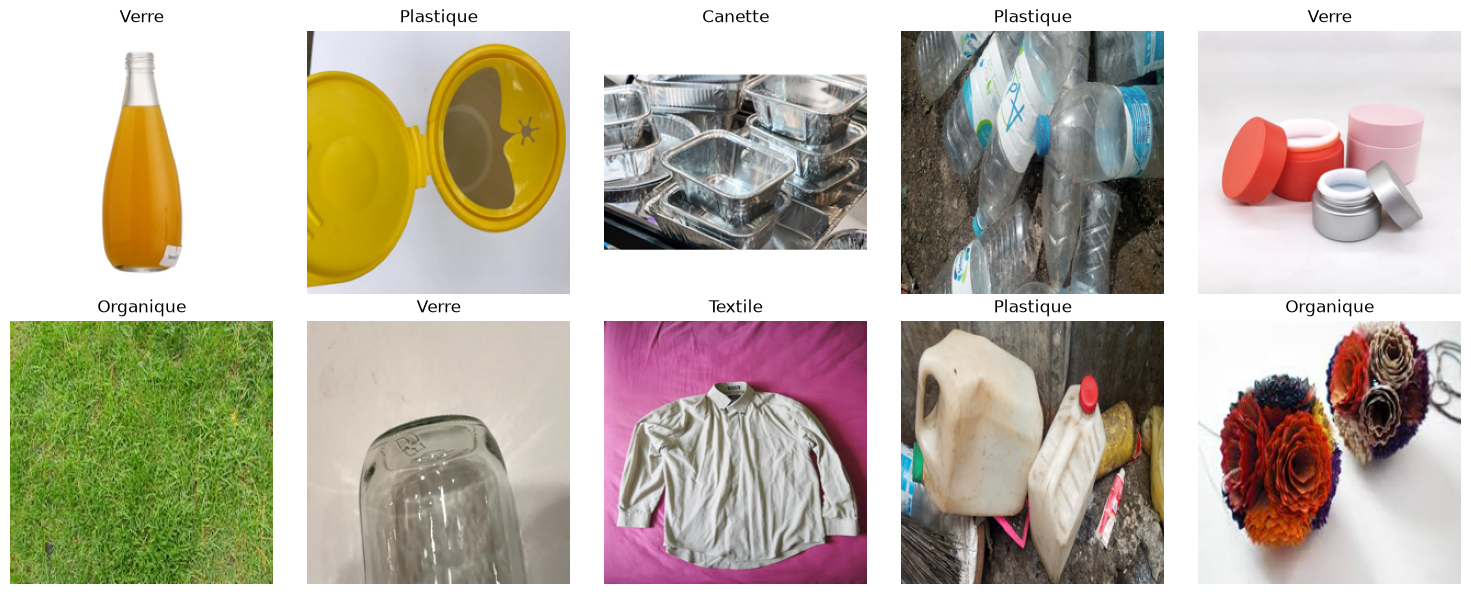

In [7]:
df.plot(n_samples=10)

KeyError: "There is no item named 'images.npy' in the archive"

## 2. Géométrie — manifolds

Test unitaire rapide : inversion expmap0/logmap0, symétrie de la distance, projection.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 2
from mccl.geometry.manifolds import Euclidean, Sphere, Hyperbolic, ProductManifold

m_e = Euclidean(4)
m_h = Hyperbolic(4, curvature=1.0)
m_s = Sphere(4)
m_p = ProductManifold([m_e, m_h, m_s])

v = torch.randn(5, 9) * 0.3
v[..., 4] = 0.0   # composante sphère : tangent en e0
y = m_p.expmap0(v)
v2 = m_p.logmap0(y)

print("expmap/logmap inverse :", torch.allclose(v, v2, atol=1e-5))
print("dist symétrique      :", torch.allclose(m_p.dist(y, y+0.1), m_p.dist(y+0.1, y), atol=1e-6))
print("dist_sq == dist**2   :", torch.allclose(m_p.dist_sq(y, y+0.1), m_p.dist(y, y+0.1)**2, atol=1e-6))

## 3. Régulariseurs et diagnostics

In [ ]:
# mccl/notebooks/main.ipynb — cellule 3
from mccl.geometry.regularizers import combined_reg
from mccl.geometry.diagnostics import delta_hyperbolicity, distortion

reg = combined_reg(y, m_p)
print("L_reg =", float(reg))

pts = m_h.expmap0(torch.randn(64, 4) * 0.1)
print("delta-hyperbolicity =", delta_hyperbolicity(pts))
print("distortion          =", distortion(pts, pts))

## 4. Backbone DINOv2

Chargement de DINOv2-small via torch.hub, troncature à 10 blocs, gel des poids.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 4
from mccl.models.backbone import DinoV2Backbone

bb = DinoV2Backbone(name="dinov2-small", num_blocks=10, frozen=True).to(device)
x = torch.randn(2, 3, 224, 224, device=device)
with torch.no_grad():
    tokens = bb(x)
print("tokens :", tokens.shape, "(B, N, D attendu)")
print("embed_dim =", bb.embed_dim)

## 5. Tête variété + modèle JEPA

Assemblage complet : backbone → ManifoldHead → Predictor → PrototypeClassifier.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 5
from mccl.config import ModelCfg
from mccl.models.jepa import JepaModel

cfg = ModelCfg()
cfg.backbone.frozen = True   # on garde le tronc gelé pour ce test
model = JepaModel(cfg).to(device)

# 2 classes fictives
model.classifier.add_class(0)
model.classifier.add_class(1)

with torch.no_grad():
    out = model(x)
print("tokens     :", out.tokens.shape)
print("global     :", out.global_embed.shape)
print("logits     :", None if out.logits is None else out.logits.shape)

## 6. Prédiction JEPA masquée

On génère un masque contexte/cible et on calcule la perte d_M².

In [ ]:
# mccl/notebooks/main.ipynb — cellule 6
from mccl.data.masking import random_block_mask
from mccl.training.losses import jepa_loss, classification_loss

ctx_idx, tgt_idx = random_block_mask(grid_h=16, grid_w=16, n_context=64, n_target=32)
with torch.no_grad():
    out = model(x, ctx_idx=ctx_idx.to(device), tgt_idx=tgt_idx.to(device))

loss_jepa = jepa_loss(out.pred, out.target, model.head.manifold)
loss_cls = classification_loss(out.logits, torch.zeros(x.size(0), dtype=torch.long, device=device))
print("loss JEPA =", float(loss_jepa))
print("loss CLS  =", float(loss_cls))

## 7. Chargement des données — MCCLImageLoader

Deux cas :
- **A.** vous avez déjà `data/raw/<classe>/*.jpg` sur disque ;
- **B.** vous voulez tester sur des images synthétiques (repli automatique).

In [ ]:
# mccl/notebooks/main.ipynb — cellule 7
from mccl.data.loader import MCCLImageLoader
from mccl.data.splits import stratified_group_split, save_splits

class_to_idx = {"cardboard": 0, "glass": 1, "metal": 2, "paper": 3, "plastic": 4}
raw_dir = ROOT / "data" / "raw"

if raw_dir.exists() and any(raw_dir.rglob("*.jpg")):
    loader = MCCLImageLoader(str(raw_dir), class_to_idx).scan().deduplicate()
    print("Index réel :", len(loader), "images")
else:
    print("Pas d'images réelles — création d'un index synthétique pour test.")
    loader = None

# Repli synthétique
if loader is None or len(loader) == 0:
    from dataclasses import dataclass
    @dataclass
    class _R:
        path: str; label: str; group: str; width: int; height: int; channels: int
    loader = MCCLImageLoader.__new__(MCCLImageLoader)
    loader.root = raw_dir
    loader.class_to_idx = class_to_idx
    loader.group_key = "source_id"
    loader.index = [
        _R(path=f"synthetic/{cls}_{i}.png", label=cls, group=f"g{i%5}",
           width=224, height=224, channels=3)
        for cls in class_to_idx for i in range(20)
    ]
    print("Index synthétique :", len(loader), "images")

## 8. Splits stratifiés par groupe (anti-fuite)

In [ ]:
# mccl/notebooks/main.ipynb — cellule 8
import numpy as np

labels = np.array([class_to_idx[r.label] for r in loader.index])
groups = np.array([r.group for r in loader.index])

tr, va, te = stratified_group_split(labels, groups, seed=0)
print("train / val / test :", len(tr), len(va), len(te))

g_tr = set(groups[tr]); g_va = set(groups[va]); g_te = set(groups[te])
print("Pas de fuite train/val :", g_tr.isdisjoint(g_va))
print("Pas de fuite train/test:", g_tr.isdisjoint(g_te))

save_splits(str(ROOT / "data" / "splits" / "waste5.json"),
            {"train": tr, "val": va, "test": te})

## 9. TaskStream incrémental

Ordre de classes : [0,1,2,3,4] → tâche 1 = {0,1}, puis +1 classe par tâche.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 9
from mccl.data.incremental import TaskStream

stream = TaskStream(labels, order=[0,1,2,3,4])
for task in stream:
    print(f"tâche {task.index} : classes={task.classes}, n_train={len(task.train_idx)}")

## 10. Mémoire duale et surprise

In [ ]:
# mccl/notebooks/main.ipynb — cellule 10
from mccl.continual.memory import FastMemory, SlowMemory
from mccl.continual.surprise import SurpriseScorer

fast = FastMemory(capacity=16)
slow = SlowMemory(capacity_per_class=4)
surprise = SurpriseScorer()

# Simule 3 batches
for _ in range(3):
    xb = torch.randn(8, 3, 224, 224)
    yb = torch.randint(0, 2, (8,))
    fast.add(xb, yb)
    err = torch.rand(8)
    s = surprise.update(err)

print("FastMemory :", len(fast), "éléments")
slow.update(0, torch.randn(10, 384))
print("prototype classe 0 :", slow.prototype(0).shape)
print("surprise normalisée :", s.mean().item(), "±", s.std().item())

## 11. Boucle d'entraînement — smoke test

On entraîne 2 époques sur 2 classes fictives avec un `DataLoader` de tenseurs aléatoires, pour vérifier que la boucle tourne et que la perte décroît.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 11
from mccl.training.optim import build_optimizer
from mccl.training.losses import classification_loss

model.train()
opt = build_optimizer(model, lr=1e-3)
losses = []

for epoch in range(2):
    for _ in range(5):
        xb = torch.randn(4, 3, 224, 224, device=device)
        yb = torch.randint(0, 2, (4,), device=device)
        out = model(xb)
        loss = classification_loss(out.logits, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(float(loss))

print("pertes :", [f"{l:.3f}" for l in losses])

## 12. Évaluation et métriques

Accuracy, matrice de confusion, oubli, transfert arrière, AUROC OOD.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 12
from mccl.evaluation.metrics import accuracy, per_class_accuracy, confusion_matrix
from mccl.evaluation.continual_metrics import average_accuracy, forgetting, backward_transfer
from mccl.evaluation.ood_metrics import auroc, fpr_at_95_tpr

logits = torch.randn(32, 2)
y = torch.randint(0, 2, (32,))
print("accuracy :", accuracy(logits, y))
print("per-class:", per_class_accuracy(logits, y, 2))
print("confusion:\n", confusion_matrix(logits, y, 2))

acc_matrix = np.array([[0.9, np.nan, np.nan],
                       [0.8, 0.85, np.nan],
                       [0.7, 0.75, 0.80]])
print("avg acc  :", average_accuracy(acc_matrix))
print("forgetting:", forgetting(acc_matrix))
print("bwt      :", backward_transfer(acc_matrix))

id_scores = np.random.rand(100)
ood_scores = np.random.rand(100) + 0.5
print("AUROC   :", auroc(id_scores, ood_scores))
print("FPR@95  :", fpr_at_95_tpr(id_scores, ood_scores))

## 13. Sonde géométrique (geometry_probe)

Lancement du script `scripts/geometry_probe.py` directement depuis le notebook.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 13
import subprocess, sys
res = subprocess.run(
    [sys.executable, "scripts/geometry_probe.py",
     "--n-samples", "32", "--batch", "8", "--num-blocks", "10",
     "--device", device],
    capture_output=True, text=True
)
print(res.stdout[-2000:])
print("STDERR:", res.stderr[-500:])

## 14. Lancement d'une expérience incrémentale

Une fois les tests ci-dessus validés, lancer une vraie expérience.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 14
import subprocess, sys
res = subprocess.run(
    [sys.executable, "scripts/run_incremental.py",
     "--exp", "configs/experiment/incr_waste5_mixed_dual.yaml",
     "--out", "results"],
    capture_output=True, text=True
)
print(res.stdout[-3000:])
print("STDERR:", res.stderr[-1000:])

## 15. Analyse des résultats

Tableau récapitulatif des runs.

In [ ]:
# mccl/notebooks/main.ipynb — cellule 15
import subprocess, sys
res = subprocess.run(
    [sys.executable, "scripts/analyze_results.py", "--dir", "results"],
    capture_output=True, text=True
)
print(res.stdout[-3000:])
print("STDERR:", res.stderr[-1000:])

## Récapitulatif

| Étape | Ce qui est testé |
|---|---|
| 1 | Seeds, chemins, device |
| 2 | Manifolds (exp/log inverse, symétrie, dist_sq) |
| 3 | Régulariseurs, diagnostics (δ-hyperbolicité, distorsion) |
| 4 | Backbone DINOv2 tronqué et gelé |
| 5 | Assemblage JEPA complet |
| 6 | Masque JEPA et perte d_M² |
| 7-8 | Chargement des données, dédoublonnage, splits anti-fuite |
| 9 | TaskStream incrémental |
| 10 | Mémoire duale, surprise |
| 11 | Boucle d'entraînement (smoke test) |
| 12 | Métriques (accuracy, oubli, bwt, AUROC, FPR@95) |
| 13 | Script `geometry_probe.py` |
| 14 | Expérience incrémentale complète |
| 15 | Analyse des résultats |

**Si une cellule échoue**, c'est le fichier correspondant dans `src/mccl/` qui doit être complété en priorité (l'ordre du notebook suit celui de développement).